# Evaluating out-of-distribution detector

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.svm import SVC

In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500_af_training.csv', index_col='id')
sequences['fold'] = sequences['fold'].astype(str)
sequences['type'] = sequences['label'].map(lambda label: 'Binding' if label else 'Non-Binding')
sequences['source_label'] = sequences['source'].map(lambda source: int(source == 'Sequences'))

In [4]:
pca = pd.read_csv('../data/interim/af3_af3_tcrmodel2_full_pae_pca.csv')
pca = pca.merge(sequences, how='left', left_on='name', right_index=True)

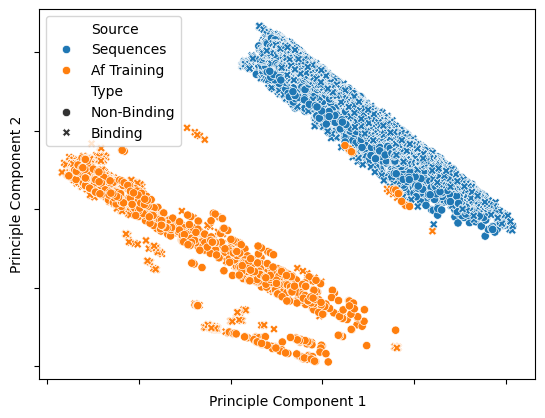

In [5]:
ax = sns.scatterplot(pca, x='pc1', y='pc2', hue='source', style='type')

ax.set_xticklabels([])
ax.set_yticklabels([])

ax.set_xlabel('Principle Component 1')
ax.set_ylabel('Principle Component 2')

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=[label.title() for label in labels])

plt.savefig('../report/figures/PAE_PCA.svg')
plt.show()

In [6]:
names = []
seeds = []
samples = []
predictions = []

for fold in sorted(pca['fold'].unique()):
    X_train = pca.loc[pca['fold'] != fold, ['pc1', 'pc2']].to_numpy()
    y_train = pca.loc[pca['fold'] != fold, 'source_label'].to_numpy()

    model = SVC(kernel='linear', random_state=SEED).fit(X_train, y_train)

    X_test = pca.loc[pca['fold'] == fold, ['pc1', 'pc2']].to_numpy()

    fold_predictions = model.predict(X_test)

    names.extend(pca.loc[pca['fold'] == fold, 'name'].tolist())
    seeds.extend(pca.loc[pca['fold'] == fold, 'seed'].tolist())
    samples.extend(pca.loc[pca['fold'] == fold, 'sample'].tolist())

    predictions.extend(fold_predictions)

svm_pca_predictions = pd.DataFrame(
    {
        'name': names,
        'seed': seeds,
        'sample': samples,
        'prediction': predictions,
    }
)

In [7]:
svm_pca_predictions = svm_pca_predictions.merge(sequences, how='left', left_on='name', right_index=True)

ROC-AUC: 0.993939393939394


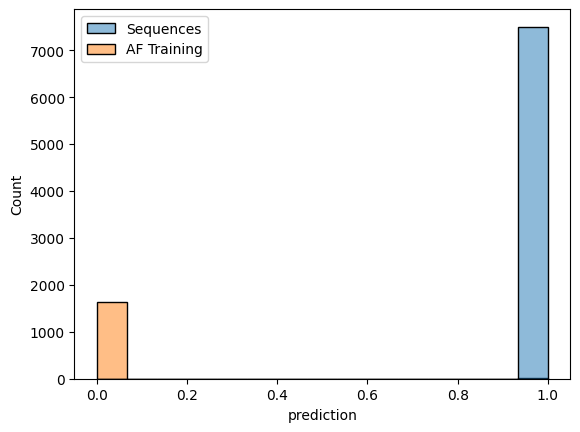

In [8]:
ax = sns.histplot(svm_pca_predictions, x='prediction', hue='source')

legend = ax.get_legend()
legend.set_title(None)

print('ROC-AUC:', roc_auc_score(svm_pca_predictions['source_label'], svm_pca_predictions['prediction']))

plt.show()

In [9]:
rng = np.random.default_rng(SEED)

svm_pca_predictions_bootstrap = {
    'sample_num': [],
    'roc_auc': [],
}
for sample_num in range(1, NUM_SAMPLES + 1):
    sample = svm_pca_predictions.sample(SAMPLE_SIZE, random_state=rng)
    roc_auc = roc_auc_score(sample['source_label'], sample['prediction'])

    svm_pca_predictions_bootstrap['sample_num'].append(sample_num)
    svm_pca_predictions_bootstrap['roc_auc'].append(roc_auc)

svm_pca_predictions_bootstrap = pd.DataFrame(svm_pca_predictions_bootstrap)

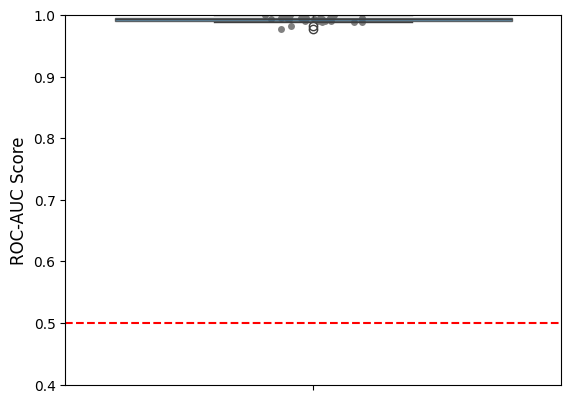

In [10]:
fig, ax = plt.subplots(1, 1)

sns.stripplot(svm_pca_predictions_bootstrap, y='roc_auc', color='grey', ax=ax, zorder=1)
sns.boxplot(svm_pca_predictions_bootstrap, y='roc_auc', ax=ax, color='tab:blue', boxprops={'alpha': 0.75}, zorder=2)

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_ylim([0.4, 1.0])

ax.set_ylabel('ROC-AUC Score', fontsize=12)

plt.show()